# Social Phobia Detection in UK Schools — ML Pipeline

**Dataset**: UKDA Study 8467 — Mental Health of Children and Young People in England 2017 (MHCYP 2017)  
**Target**: ICD-10 clinical diagnosis of social phobia (`spin_risk_binary`)  
**Schema**: v2.0 — SDQ subscales + WEMWBS wellbeing  
**Design**: True nested cross-validation with school-group isolation

---
## Sections
1. Setup & Configuration
2. Data Loading & Exploration
3. Schema Validation
4. Feature Engineering
5. Preprocessing
6. Nested CV Training
7. Results & Visualisation
8. Feature Importance

## 1. Setup & Configuration

In [1]:
import sys
import os
import warnings
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.metrics import (
    RocCurveDisplay, PrecisionRecallDisplay,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.WARNING)

# Locate project root regardless of where Jupyter was launched from
def _find_project_root() -> Path:
    """Walk up from cwd until we find config/model_registry.yaml."""
    candidate = Path('.').resolve()
    for folder in [candidate] + list(candidate.parents):
        if (folder / 'config' / 'model_registry.yaml').exists():
            return folder
    raise RuntimeError(f"Cannot find project root from {candidate}")

PROJECT_ROOT = _find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import Config
from src.data_loader import load_active_dataset
from src.schema_validator import SchemaValidator
from src.feature_engineering import FeatureEngineer
from src.preprocessing import Preprocessor, apply_smote
from src.train import run_training_pipeline

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

cfg = Config()
print(f'Project root   : {PROJECT_ROOT}')
print(f'Schema version : {cfg.schema_version}')
print(f'Active dataset : {cfg.active_dataset_key}  →  {cfg.active_dataset_path}')
print(f'Model features : {len(cfg.model_feature_cols)}')
print(f'Target column  : {cfg.primary_target_col}')

Project root   : /Users/mahesh/social-phobia-research
Schema version : 2.0
Active dataset : real_v1  →  data/raw/real_v1.csv
Model features : 22
Target column  : spin_risk_binary


## 2. Data Loading & Exploration

In [2]:
df_raw, meta = load_active_dataset(cfg)
print(f'Shape: {df_raw.shape}   ({df_raw.shape[0]:,} participants × {df_raw.shape[1]} columns)')
print(f'Schools (PSU clusters): {df_raw["school_id"].nunique()}')
df_raw.head(3)

Shape: (3749, 29)   (3,749 participants × 29 columns)
Schools (PSU clusters): 457


,participant_id,school_id,cohort_wave,consent_obtained,data_quality_flag,spin_items_missing,spin_complete_flag,spin_risk_binary,age_years,gender,...,psdq_total,sdq_emotional,sdq_peer,sdq_conduct,sdq_hyper,sdq_prosocial,sdq_total,wellbeing_wemwbs,bullied_flag,cyberbullied_flag
0,104054,1860,2017,1,0,0,1,0,17,male,...,8,2,1,1,3,8,7,53.0,1,0
1,102197,1860,2017,1,0,4,0,0,17,female,...,<NA>,5,4,2,6,10,17,49.0,0,0
2,108620,1860,2017,1,0,4,0,0,17,female,...,<NA>,9,1,2,3,8,15,45.0,1,1


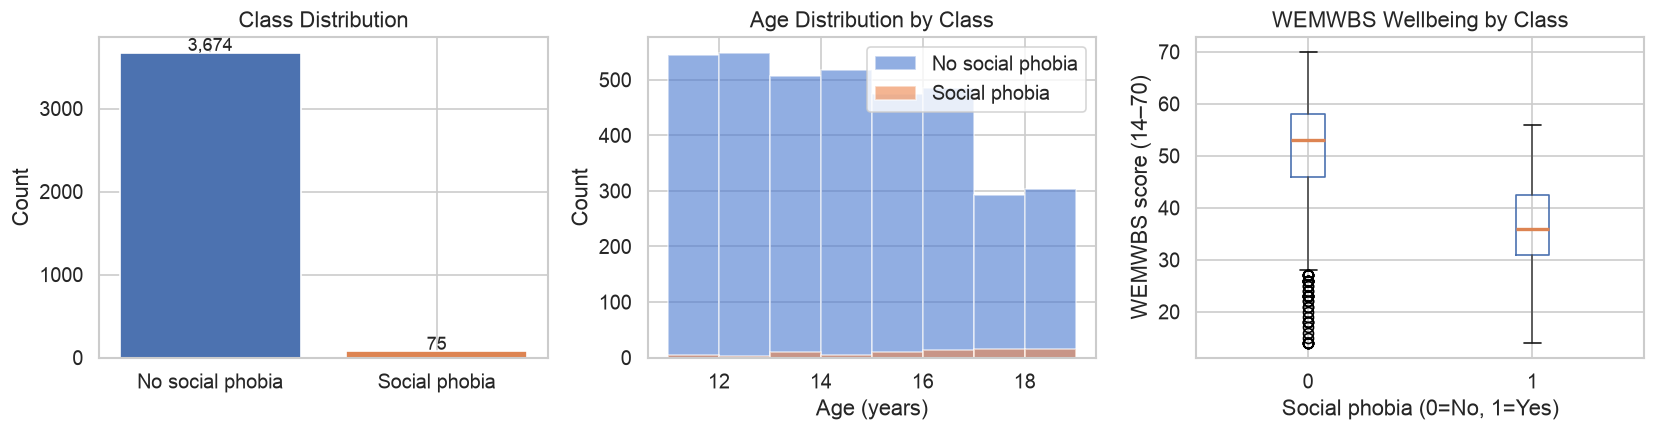


Prevalence: 75 / 3,749 = 2.00%  (ratio 1:48)


In [3]:
# Class distribution
target = cfg.primary_target_col
counts = df_raw[target].value_counts().sort_index()
prevalence = df_raw[target].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# (a) Target distribution
axes[0].bar(['No social phobia', 'Social phobia'], counts.values,
            color=['#4C72B0', '#DD8452'], edgecolor='white')
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v:,}', ha='center', fontsize=11)

# (b) Age distribution by class
for label, grp in df_raw.groupby(target):
    lbl = 'Social phobia' if label == 1 else 'No social phobia'
    axes[1].hist(grp['age_years'], bins=range(11, 20), alpha=0.6, label=lbl, edgecolor='white')
axes[1].set_title('Age Distribution by Class')
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Count')
axes[1].legend()

# (c) WEMWBS by class
df_raw.boxplot(column='wellbeing_wemwbs', by=target, ax=axes[2],
               boxprops=dict(color='#4C72B0'),
               medianprops=dict(color='#DD8452', linewidth=2))
axes[2].set_title('WEMWBS Wellbeing by Class')
axes[2].set_xlabel('Social phobia (0=No, 1=Yes)')
axes[2].set_ylabel('WEMWBS score (14–70)')
plt.suptitle('')

plt.tight_layout()
plt.show()
print(f'\nPrevalence: {counts[1]:,} / {len(df_raw):,} = {prevalence:.2f}%  (ratio 1:{int(counts[0]/counts[1])})')

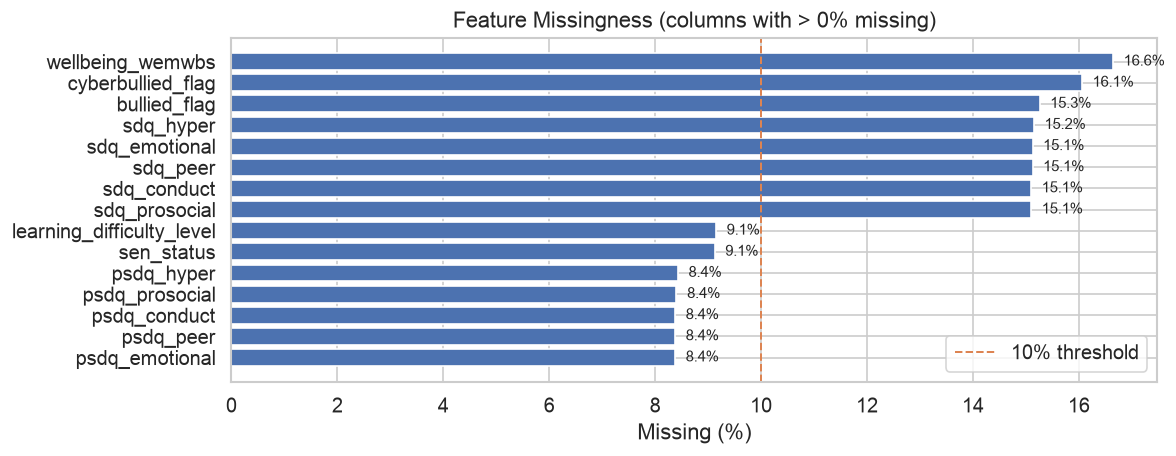

In [4]:
# Missingness heatmap (top 15 columns by missing count)
model_cols = [c for c in cfg.model_feature_cols if c in df_raw.columns]
miss = df_raw[model_cols].isnull().mean().sort_values(ascending=False)
miss = miss[miss > 0].head(15)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(miss.index[::-1], miss.values[::-1] * 100, color='#4C72B0', edgecolor='white')
ax.set_xlabel('Missing (%)')
ax.set_title('Feature Missingness (columns with > 0% missing)')
ax.axvline(10, color='#DD8452', linestyle='--', linewidth=1.2, label='10% threshold')
ax.legend()
for bar, val in zip(bars, miss.values[::-1]):
    ax.text(val * 100 + 0.2, bar.get_y() + bar.get_height()/2,
            f'{val*100:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

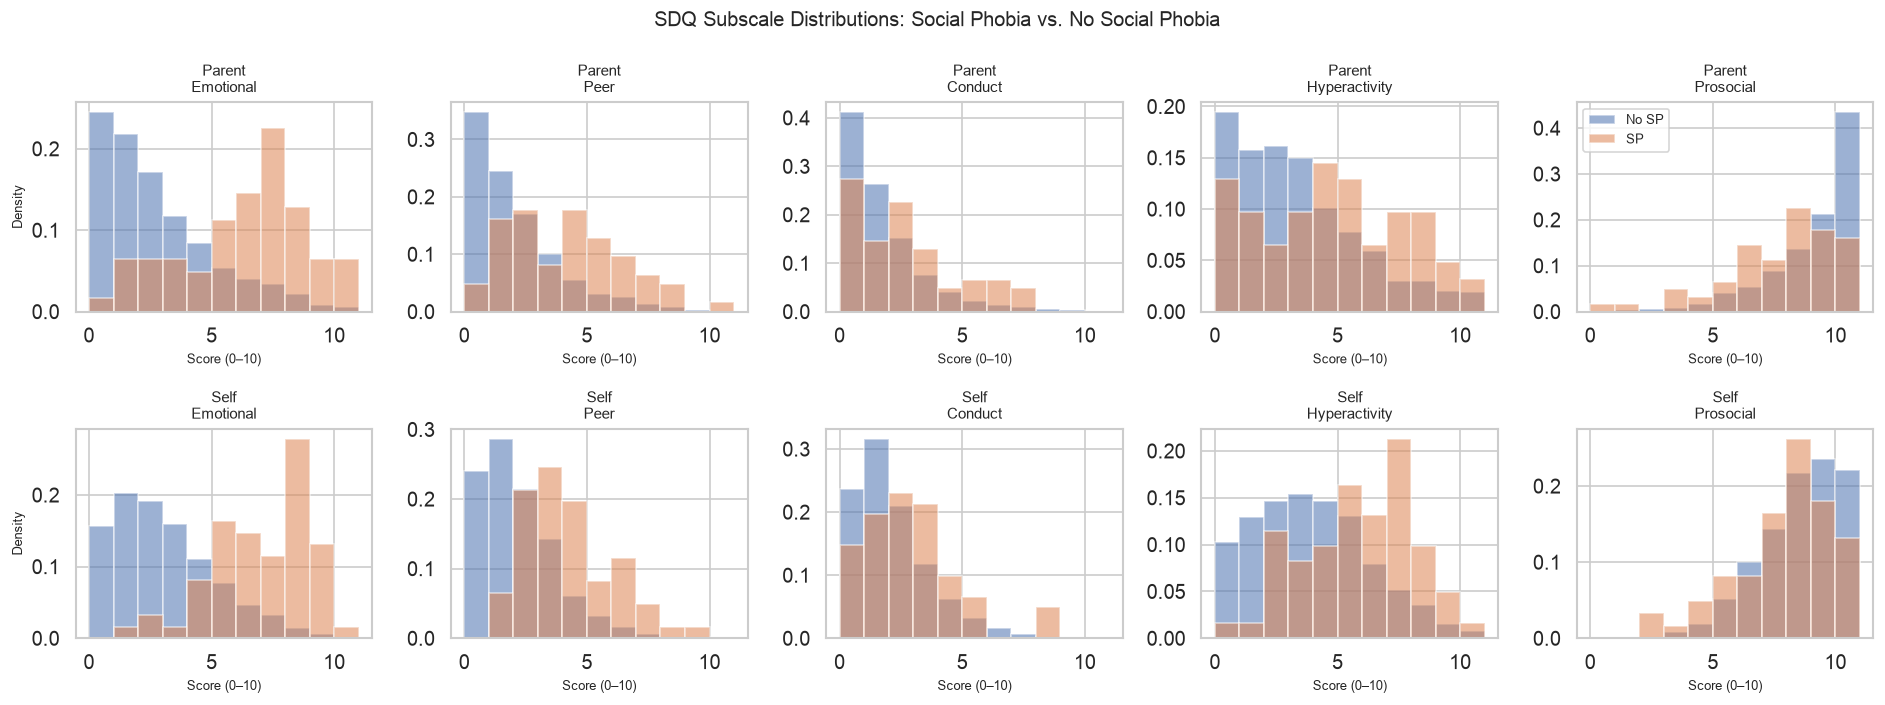

In [5]:
# SDQ subscale comparison: at-risk vs. not at-risk
sdq_pairs = [
    ('psdq_emotional', 'sdq_emotional', 'Emotional'),
    ('psdq_peer',      'sdq_peer',      'Peer'),
    ('psdq_conduct',   'sdq_conduct',   'Conduct'),
    ('psdq_hyper',     'sdq_hyper',     'Hyperactivity'),
    ('psdq_prosocial', 'sdq_prosocial', 'Prosocial'),
]

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=False)
for col_idx, (p_col, s_col, label) in enumerate(sdq_pairs):
    for row_idx, (col, rater) in enumerate([(p_col, 'Parent'), (s_col, 'Self')]):
        ax = axes[row_idx][col_idx]
        for cls_val, color, cls_label in [(0, '#4C72B0', 'No SP'), (1, '#DD8452', 'SP')]:
            vals = df_raw.loc[df_raw[target] == cls_val, col].dropna()
            ax.hist(vals, bins=range(0, 12), alpha=0.55, color=color, label=cls_label,
                    edgecolor='white', density=True)
        ax.set_title(f'{rater}\n{label}', fontsize=9)
        ax.set_xlabel('Score (0–10)', fontsize=8)
        if col_idx == 0:
            ax.set_ylabel('Density', fontsize=8)
        if row_idx == 0 and col_idx == 4:
            ax.legend(fontsize=8)

plt.suptitle('SDQ Subscale Distributions: Social Phobia vs. No Social Phobia', fontsize=12)
plt.tight_layout()
plt.show()

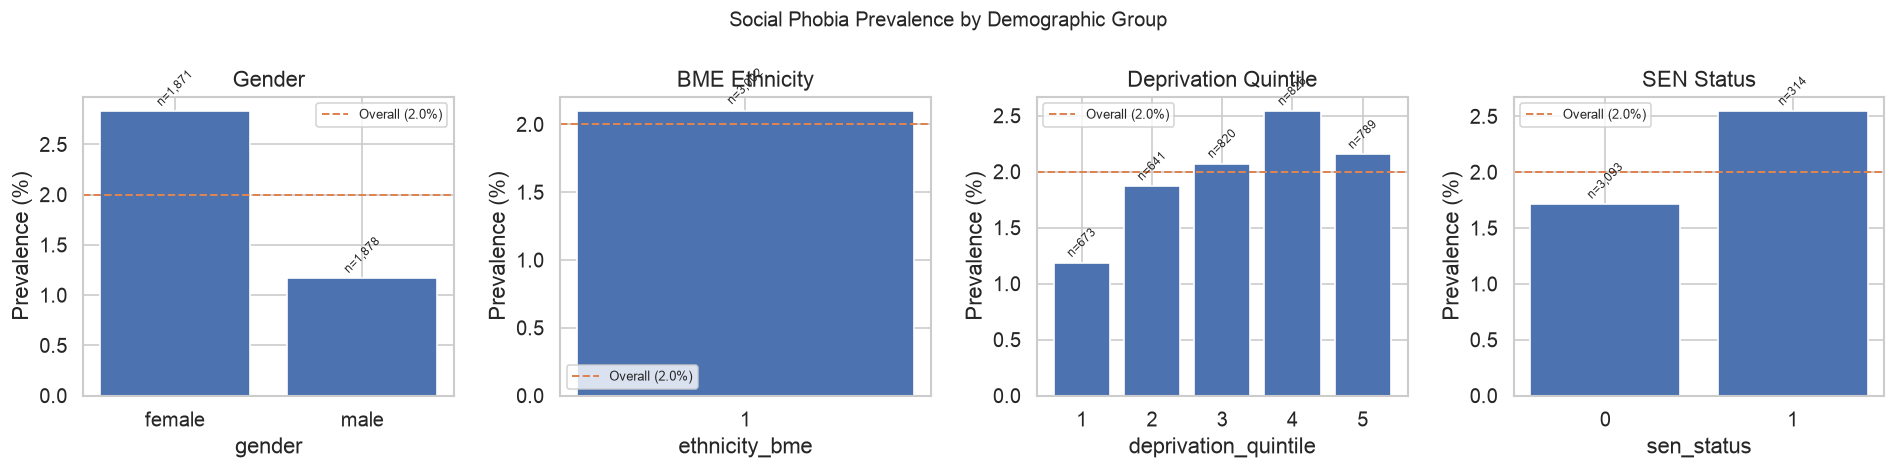

In [6]:
# Demographic breakdown
demo_cols = {'gender': 'Gender', 'ethnicity_bme': 'BME Ethnicity',
             'deprivation_quintile': 'Deprivation Quintile', 'sen_status': 'SEN Status'}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, title) in zip(axes, demo_cols.items()):
    if col not in df_raw.columns:
        continue
    rates = df_raw.groupby(col)[target].mean() * 100
    n_per = df_raw.groupby(col)[target].count()
    bars = ax.bar(rates.index.astype(str), rates.values, color='#4C72B0', edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel('Prevalence (%)')
    ax.axhline(prevalence, color='#DD8452', linestyle='--', linewidth=1.2, label=f'Overall ({prevalence:.1f}%)')
    ax.legend(fontsize=8)
    for bar, (idx, n) in zip(bars, n_per.items()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                f'n={n:,}', ha='center', fontsize=7, rotation=45)

plt.suptitle('Social Phobia Prevalence by Demographic Group', fontsize=12)
plt.tight_layout()
plt.show()

## 3. Schema Validation

In [7]:
validator = SchemaValidator(cfg)
report = validator.validate(df_raw, cfg.active_dataset_key)
print(report.summary())

Schema validation PASSED — real_v1
  Rows: 3749 | Columns: 29
  Errors  : 0
  Warnings: 1
  ── WARNINGS ──
    • 'spin_items_missing' disagrees with computed item-level missingness for 316 row(s). Consider recomputing the column.


## 4. Feature Engineering

In [8]:
# Full dataset — no exclusion criteria applied (matches the actual v5 pipeline)
df_fe_input = df_raw.copy()
print(f'Dataset: {len(df_fe_input):,} participants × {df_fe_input.shape[1]} columns')
print(f'Social phobia cases: {int(df_fe_input[target].sum())} ({df_fe_input[target].mean()*100:.2f}%)')

Dataset: 3,749 participants × 29 columns
Social phobia cases: 75 (2.00%)


In [9]:
fe = FeatureEngineer(cfg)
df_fe = fe.transform(df_fe_input.copy())

# Show derived features
derived = fe.engineered_col_names()
print('Derived features computed:')
for col in derived:
    non_null = df_fe[col].notna().sum()
    print(f'  {col:<30}  non-null: {non_null:,} / {len(df_fe):,}')

df_fe[derived].describe().round(2)

Derived features computed:
  sdq_internalising               non-null: 3,181 / 3,749
  psdq_internalising              non-null: 3,435 / 3,749
  parent_self_discrepancy         non-null: 2,864 / 3,749
  wellbeing_low_flag              non-null: 3,125 / 3,749
  any_bullying                    non-null: 3,209 / 3,749


,sdq_internalising,psdq_internalising,parent_self_discrepancy,wellbeing_low_flag,any_bullying
count,3181.00,3435.00,2864.00,3125.0,3209.00
mean,4.40,4.01,-1.70,0.1,0.44
std,3.08,3.63,5.39,0.3,0.50
min,0.00,0.00,-27.00,0.0,0.00
25%,2.00,1.00,-5.00,0.0,0.00
50%,4.00,3.00,-2.00,0.0,0.00
75%,6.00,6.00,2.00,0.0,1.00
max,18.00,20.00,20.00,1.0,1.00


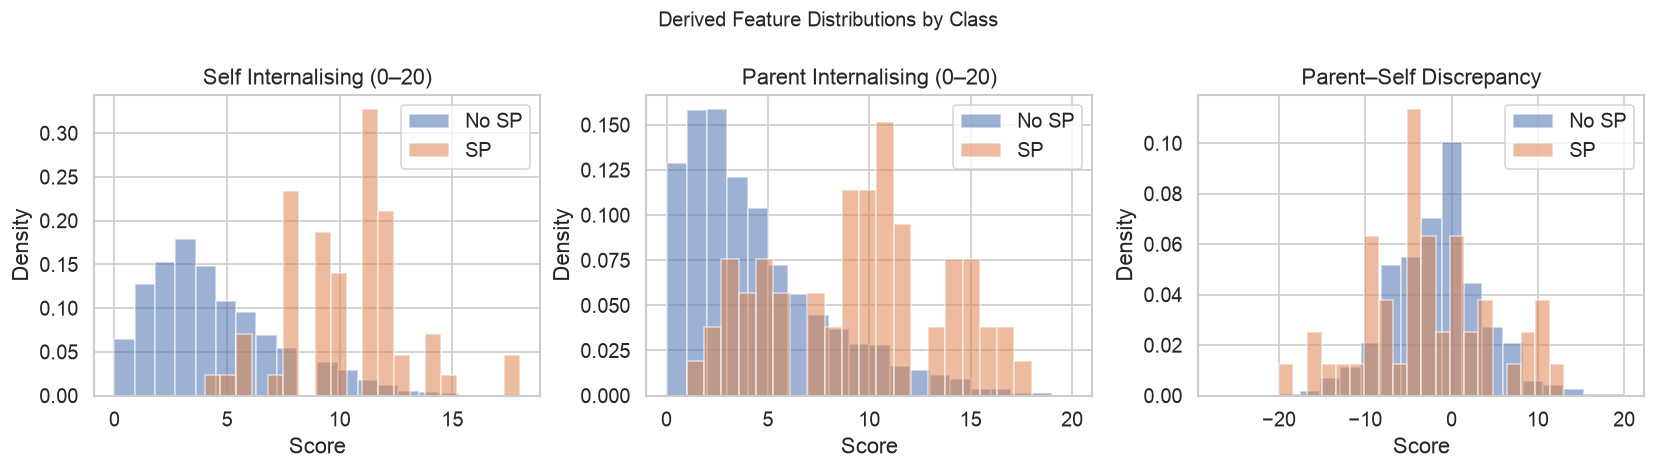

In [10]:
# Parent vs Self SDQ internalising score comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Internalising scores by class
for ax, col, title in [
    (axes[0], 'sdq_internalising',  'Self Internalising (0–20)'),
    (axes[1], 'psdq_internalising', 'Parent Internalising (0–20)'),
    (axes[2], 'parent_self_discrepancy', 'Parent–Self Discrepancy'),
]:
    for cls_val, color, lbl in [(0, '#4C72B0', 'No SP'), (1, '#DD8452', 'SP')]:
        vals = df_fe.loc[df_fe[target] == cls_val, col].dropna()
        ax.hist(vals, bins=20, alpha=0.55, color=color, label=lbl, edgecolor='white', density=True)
    ax.set_title(title)
    ax.set_xlabel('Score')
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Derived Feature Distributions by Class', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Preprocessing (single-fold demonstration)

In [11]:
# Demonstrate preprocessing on a small split
from sklearn.model_selection import train_test_split

model_cols = [c for c in cfg.model_feature_cols if c in df_fe.columns]
X_demo = df_fe[model_cols].copy()
y_demo = df_fe[target].astype(int)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42, stratify=y_demo
)

prep = Preprocessor(cfg)
X_tr_proc  = prep.fit_transform(X_tr.reset_index(drop=True))
X_val_proc = prep.transform(X_val.reset_index(drop=True))

print(f'Training set  : {X_tr.shape} → after preprocessing: {X_tr_proc.shape}')
print(f'Validation set: {X_val.shape} → after preprocessing: {X_val_proc.shape}')
print(f'Any NaN after preprocessing? Train={X_tr_proc.isnull().any().any()}  Val={X_val_proc.isnull().any().any()}')
X_tr_proc.describe().round(3)

Training set  : (2999, 22) → after preprocessing: (2999, 22)
Validation set: (750, 22) → after preprocessing: (750, 22)
Any NaN after preprocessing? Train=False  Val=False


,age_years,deprivation_quintile,sen_status,learning_difficulty_level,psdq_emotional,psdq_peer,psdq_conduct,psdq_hyper,psdq_prosocial,sdq_emotional,...,sdq_hyper,sdq_prosocial,wellbeing_wemwbs,bullied_flag,cyberbullied_flag,sdq_internalising,psdq_internalising,parent_self_discrepancy,wellbeing_low_flag,any_bullying
count,2999.000,2999.000,2999.0,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,...,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000,2999.000
mean,0.000,2.112,0.087,0.574,0.000,-0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.342,0.188,-0.000,-0.000,-0.000,0.091,0.388
std,1.000,1.386,0.281,0.743,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,0.474,0.391,1.000,1.000,1.000,0.288,0.487
min,-1.427,0.000,0.0,0.000,-1.061,-0.912,-0.821,-1.196,-4.783,-1.343,...,-1.610,-4.986,-4.177,0.000,0.000,-1.524,-1.133,-4.902,0.000,0.000
25%,-0.971,1.000,0.0,0.000,-0.620,-0.912,-0.821,-0.789,-0.311,-0.849,...,-0.716,-0.598,-0.607,0.000,0.000,-0.850,-0.856,-0.594,0.000,0.000
50%,-0.059,2.000,0.0,0.000,-0.179,-0.370,-0.197,-0.146,0.248,-0.341,...,-0.235,0.029,0.062,0.000,0.000,-0.176,-0.302,-0.012,0.000,0.000
75%,0.854,3.000,0.0,1.000,0.703,0.331,0.427,0.432,0.807,0.630,...,0.626,0.656,0.620,1.000,0.000,0.497,0.530,0.625,0.000,1.000
max,1.766,4.000,1.0,3.000,3.350,4.508,5.417,2.874,0.807,3.589,...,2.861,1.283,2.071,1.000,1.000,4.539,4.412,4.665,1.000,1.000


Before SMOTE: {0: 2939, 1: 60}  (minority=60 = 2.0%)
After SMOTE : {0: 2939, 1: 881}  (minority=881 = 23.1%)


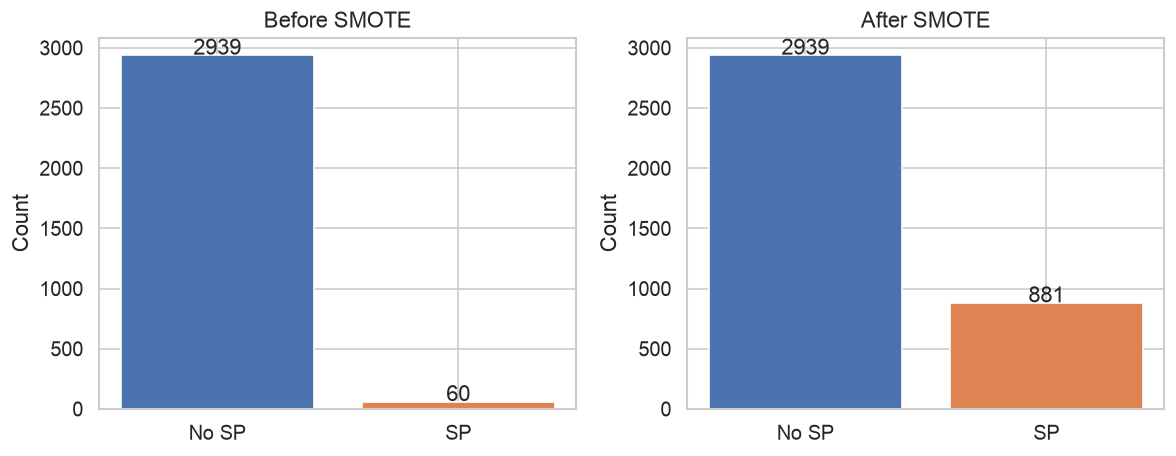

In [12]:
# SMOTE effect
print(f'Before SMOTE: {y_tr.value_counts().to_dict()}  (minority={y_tr.sum()} = {y_tr.mean()*100:.1f}%)')
X_sm, y_sm = apply_smote(X_tr_proc, y_tr.reset_index(drop=True), cfg)
print(f'After SMOTE : {y_sm.value_counts().to_dict()}  (minority={y_sm.sum()} = {y_sm.mean()*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, y, title in [(axes[0], y_tr, 'Before SMOTE'), (axes[1], y_sm, 'After SMOTE')]:
    vc = y.value_counts().sort_index()
    ax.bar(['No SP', 'SP'], vc.values, color=['#4C72B0', '#DD8452'], edgecolor='white')
    ax.set_title(title)
    ax.set_ylabel('Count')
    for i, v in enumerate(vc.values):
        ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout()
plt.show()

## 6. Nested CV Training

This runs the full pipeline — **~3–4 minutes**. Skip to Section 7 to load saved artefacts if already trained.

In [13]:
# Set RETRAIN = True ONLY to re-run the full nested CV (~3-4 min).
# Leave False to use the saved model v5 artefacts in Section 7.
RETRAIN = False

if RETRAIN:
    import logging
    logging.getLogger('src').setLevel(logging.INFO)
    results = run_training_pipeline(cfg)
    logging.getLogger('src').setLevel(logging.WARNING)
else:
    results = None
    print('Retraining skipped — using saved artefacts (model v5).')
    print('Set RETRAIN = True above to re-run the full pipeline.')

Retraining skipped — using saved artefacts (model v5).
Set RETRAIN = True above to re-run the full pipeline.


## 7. Results & Visualisation

In [14]:
# Load saved artefacts — reflects active model (v5: LogisticRegression + Platt Scaling)
import joblib, yaml

registry_path = PROJECT_ROOT / 'config' / 'model_registry.yaml'
with open(registry_path) as f:
    registry = yaml.safe_load(f)

active_ver = registry['active_model']
model_meta = registry['models'][active_ver]

print(f'Active model  : {active_ver} — {model_meta["model_name"]}')
print(f'Trained on    : {model_meta["trained_on_dataset"]}  ({model_meta["trained_date"]})')
print(f'Threshold     : {model_meta["classification_threshold"]}')
if 'calibration_method' in model_meta:
    print(f'Calibration   : {model_meta["calibration_method"]}')
print()

# v5 shares the same base LR as v4 — use v4 CV stats for cross-validation summary
cv_ver = 'v4' if active_ver == 'v5' else active_ver
cv_meta = registry['models'][cv_ver]
print(f'=== CV Performance (mean ± SD) — base model ({cv_ver}) ===')
for metric, val in cv_meta['cv_performance']['mean'].items():
    std = cv_meta['cv_performance']['std'][metric]
    print(f'  {metric:<12}  {val:.3f} ± {std:.3f}')
print()
print(f'=== Held-out Test Performance ({active_ver} — calibrated) ===')
for metric, val in model_meta['test_performance'].items():
    print(f'  {metric:<12}  {val:.4f}')

Active model  : v5 — LogisticRegression+PlattScaling
Trained on    : real_v1  (2026-07-31)
Threshold     : 0.0337
Calibration   : platt_scaling_sigmoid

=== CV Performance (mean ± SD) — base model (v4) ===
  auc_roc       0.926 ± 0.012
  f1            0.156 ± 0.042
  pr_auc        0.275 ± 0.044
  recall        0.920 ± 0.045

=== Held-out Test Performance (v5 — calibrated) ===
  auc_roc       0.9375
  brier_score   0.0189
  ece           0.0053
  pr_auc        0.1785
  precision     0.1346
  recall        0.9333


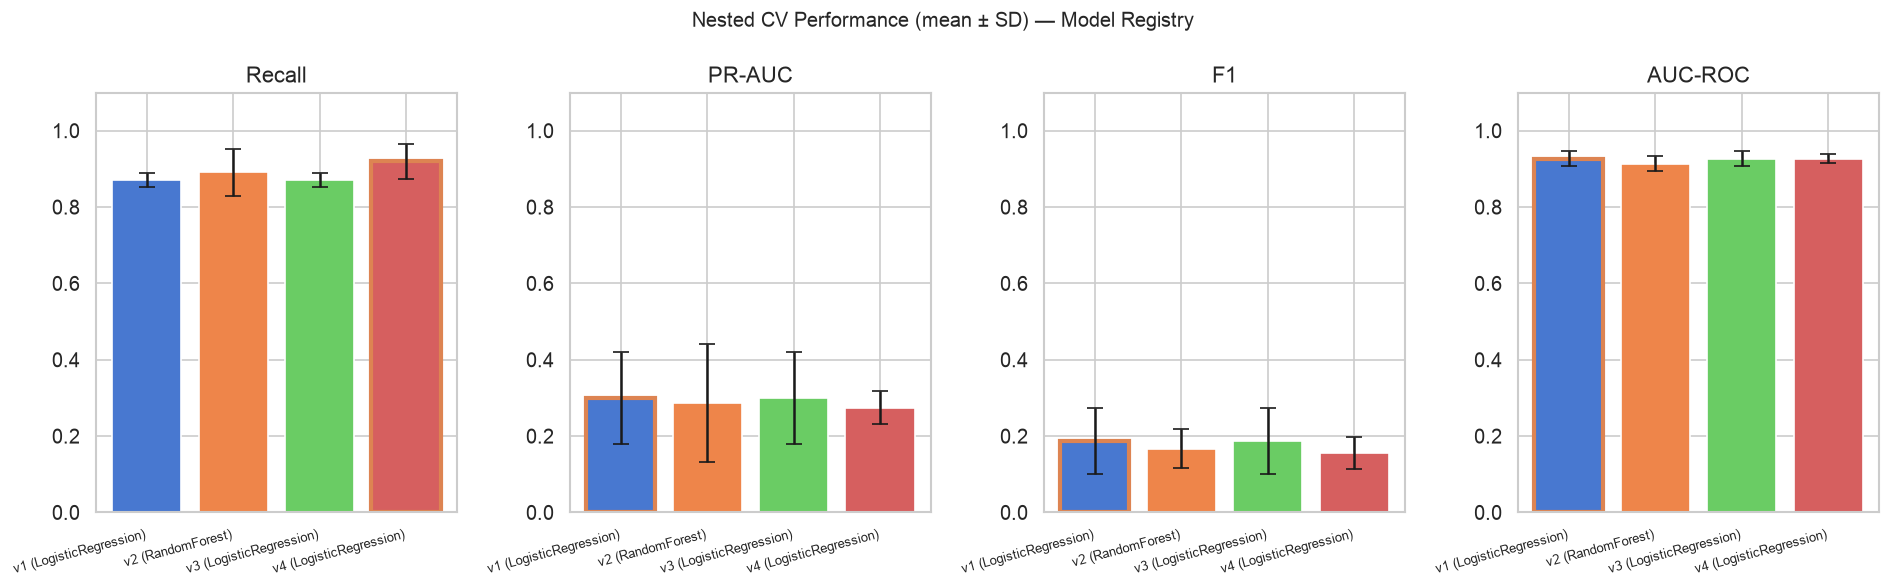


Model v5 (active) inherits v4 base LR — calibration improved ECE from 0.243 → 0.005


In [15]:
# CV performance summary from model registry (v1–v4 base models)
# Full per-fold bar chart is available when the training pipeline (Section 6) is run live.

metrics_to_plot = ['recall', 'pr_auc', 'f1', 'auc_roc']
metric_labels  = ['Recall', 'PR-AUC', 'F1', 'AUC-ROC']

# Collect mean ± SD from registry for models that have cv_performance
cv_entries = {
    ver: info for ver, info in registry['models'].items()
    if 'cv_performance' in info
}

if not cv_entries:
    print('No CV performance data in registry. Run Section 6 training pipeline first.')
else:
    model_labels = [f'{ver} ({info["model_name"]})' for ver, info in cv_entries.items()]
    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    colors = sns.color_palette('muted', len(cv_entries))

    for ax, metric, label in zip(axes, metrics_to_plot, metric_labels):
        means = [info['cv_performance']['mean'].get(metric, 0) for info in cv_entries.values()]
        stds  = [info['cv_performance']['std'].get(metric, 0) for info in cv_entries.values()]
        bars = ax.bar(range(len(cv_entries)), means, yerr=stds,
                      color=colors, edgecolor='white', capsize=5)
        ax.set_xticks(range(len(cv_entries)))
        ax.set_xticklabels(model_labels, fontsize=8, rotation=15, ha='right')
        ax.set_title(label)
        ax.set_ylim(0, 1.1)
        best_idx = int(np.argmax(means))
        bars[best_idx].set_edgecolor('#DD8452')
        bars[best_idx].set_linewidth(2.5)

    plt.suptitle('Nested CV Performance (mean ± SD) — Model Registry', fontsize=12)
    plt.tight_layout()
    plt.show()

    print('\nModel v5 (active) inherits v4 base LR — calibration improved ECE from 0.243 → 0.005')

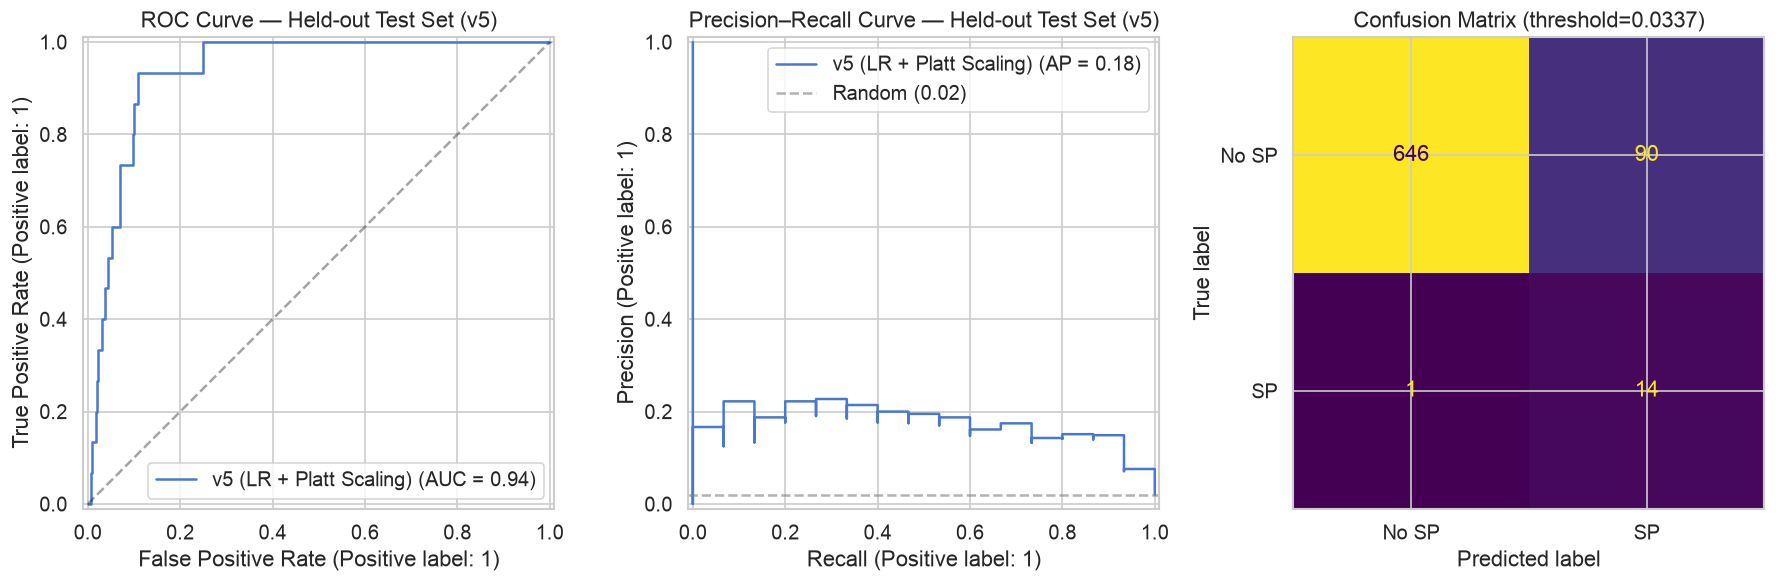

TP=14  FP=90  FN=1  TN=646
Recall (sensitivity)  : 0.933
Specificity           : 0.878
Precision (PPV)       : 0.135
NPV                   : 0.998
Number needed to screen (1/precision): 7


In [16]:
# ROC and PR curves on held-out test set — model v5 (LR + Platt Scaling)
import joblib
from sklearn.model_selection import StratifiedGroupKFold
from src.calibration import PlattCalibratedModel  # required for unpickling model_v5

final_model  = joblib.load(PROJECT_ROOT / 'models' / 'model_v5.pkl')
preprocessor = joblib.load(PROJECT_ROOT / 'models' / 'preprocessor_v5.pkl')
threshold    = registry['models']['v5']['classification_threshold']

# Reconstruct test set from full dataset using the same outer CV split
df_for_split = fe.transform(df_raw.copy())
feature_cols = [c for c in cfg.model_feature_cols if c in df_for_split.columns]
X_all = df_for_split[feature_cols]
y_all = df_for_split[target].astype(int)
groups = df_for_split[cfg.group_col]

n_splits = min(cfg.cv_outer_folds, groups.nunique())
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg.random_seed)
pool_idx, test_idx = next(iter(sgkf.split(X_all, y_all, groups=groups)))

X_test_raw = X_all.iloc[test_idx].reset_index(drop=True)
y_test = y_all.iloc[test_idx].reset_index(drop=True)
X_test_proc = preprocessor.transform(X_test_raw)

y_prob = final_model.predict_proba(X_test_proc.values)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ROC
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[0],
                                  name='v5 (LR + Platt Scaling)')
axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
axes[0].set_title('ROC Curve — Held-out Test Set (v5)')

# PR curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1],
                                        name='v5 (LR + Platt Scaling)')
axes[1].axhline(y_test.mean(), color='grey', linestyle='--', alpha=0.6,
                label=f'Random ({y_test.mean():.2f})')
axes[1].legend()
axes[1].set_title('Precision–Recall Curve — Held-out Test Set (v5)')

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No SP', 'SP']).plot(ax=axes[2], colorbar=False)
axes[2].set_title(f'Confusion Matrix (threshold={threshold:.4f})')

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TP={tp}  FP={fp}  FN={fn}  TN={tn}')
print(f'Recall (sensitivity)  : {tp/(tp+fn):.3f}')
print(f'Specificity           : {tn/(tn+fp):.3f}')
print(f'Precision (PPV)       : {tp/(tp+fp):.3f}')
print(f'NPV                   : {tn/(tn+fn):.3f}')
print(f'Number needed to screen (1/precision): {(tp+fp)/tp:.0f}')

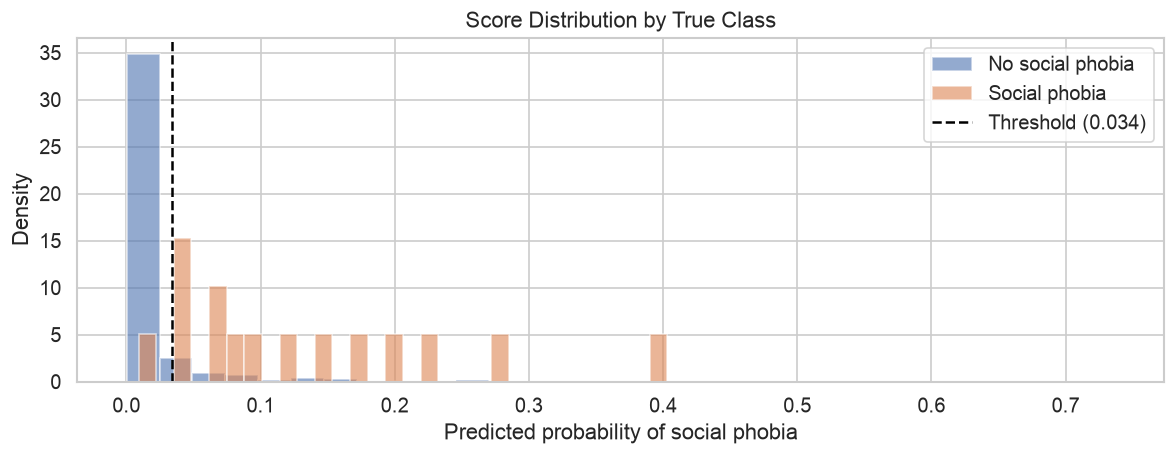

In [17]:
# Probability score distribution
fig, ax = plt.subplots(figsize=(10, 4))
for cls_val, color, lbl in [(0, '#4C72B0', 'No social phobia'), (1, '#DD8452', 'Social phobia')]:
    mask = y_test.values == cls_val
    ax.hist(y_prob[mask], bins=30, alpha=0.6, color=color, label=lbl, edgecolor='white', density=True)
ax.axvline(threshold, color='black', linestyle='--', linewidth=1.5, label=f'Threshold ({threshold:.3f})')
ax.set_xlabel('Predicted probability of social phobia')
ax.set_ylabel('Density')
ax.set_title('Score Distribution by True Class')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Feature Importance

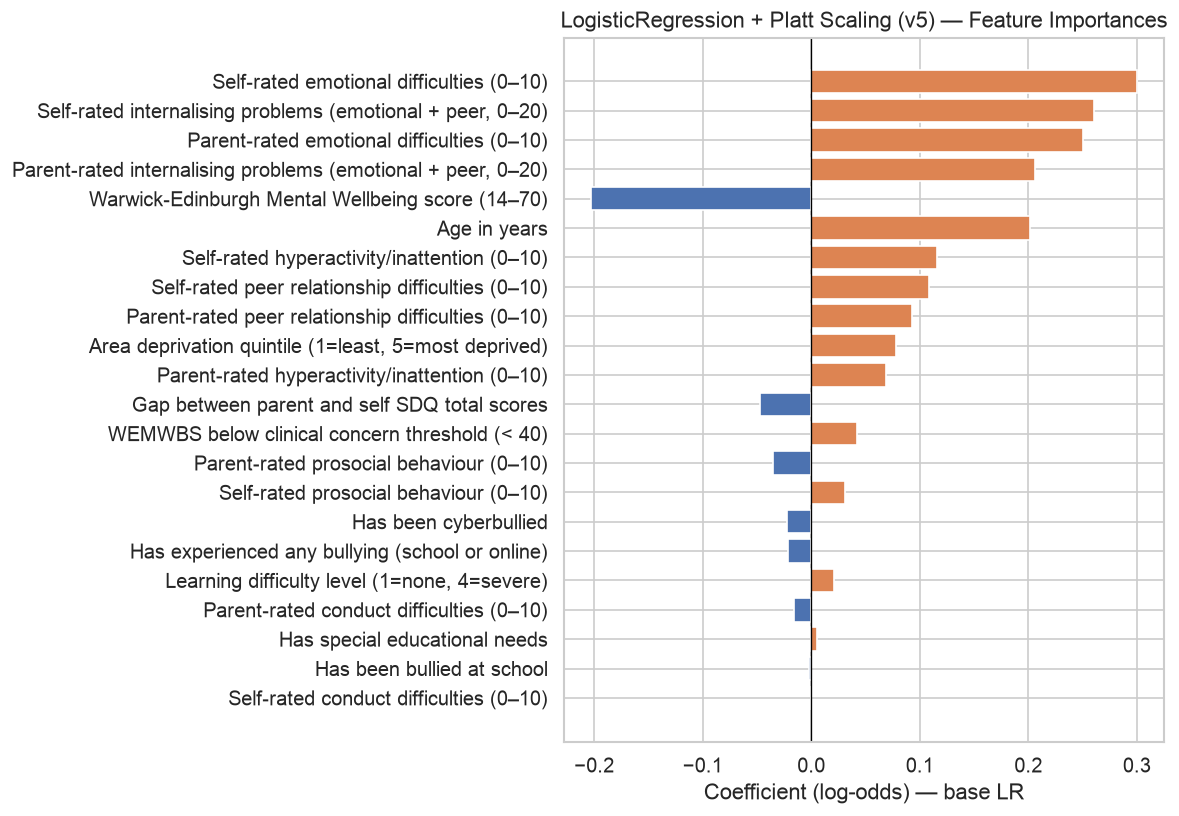

In [18]:
# Logistic Regression coefficients — v5 base model (via PlattCalibratedModel wrapper)
feature_names = [c for c in cfg.model_feature_cols if c in df_for_split.columns]
model = final_model
model_name = 'LogisticRegression + Platt Scaling (v5)'

# Unwrap PlattCalibratedModel to access the base LR's coefficients
base = getattr(model, 'base_model', model)

if hasattr(base, 'coef_'):
    importances = base.coef_[0]
    imp_label = 'Coefficient (log-odds) — base LR'
elif hasattr(base, 'feature_importances_'):
    importances = base.feature_importances_
    imp_label = 'Feature Importance (Gini)'
else:
    importances = None

if importances is not None:
    lay_labels = []
    for fn in feature_names:
        try:
            lay_labels.append(cfg.get_lay_label(fn))
        except (KeyError, AttributeError):
            lay_labels.append(fn)

    fi_df = pd.DataFrame({'feature': feature_names, 'label': lay_labels, 'importance': importances})
    fi_df = fi_df.sort_values('importance', key=abs, ascending=True)

    fig, ax = plt.subplots(figsize=(10, 7))
    colors_fi = ['#DD8452' if v > 0 else '#4C72B0' for v in fi_df['importance']]
    ax.barh(fi_df['label'], fi_df['importance'], color=colors_fi, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel(imp_label)
    ax.set_title(f'{model_name} — Feature Importances')
    plt.tight_layout()
    plt.show()
else:
    print(f'{model_name} does not expose coefficients or feature importances directly.')

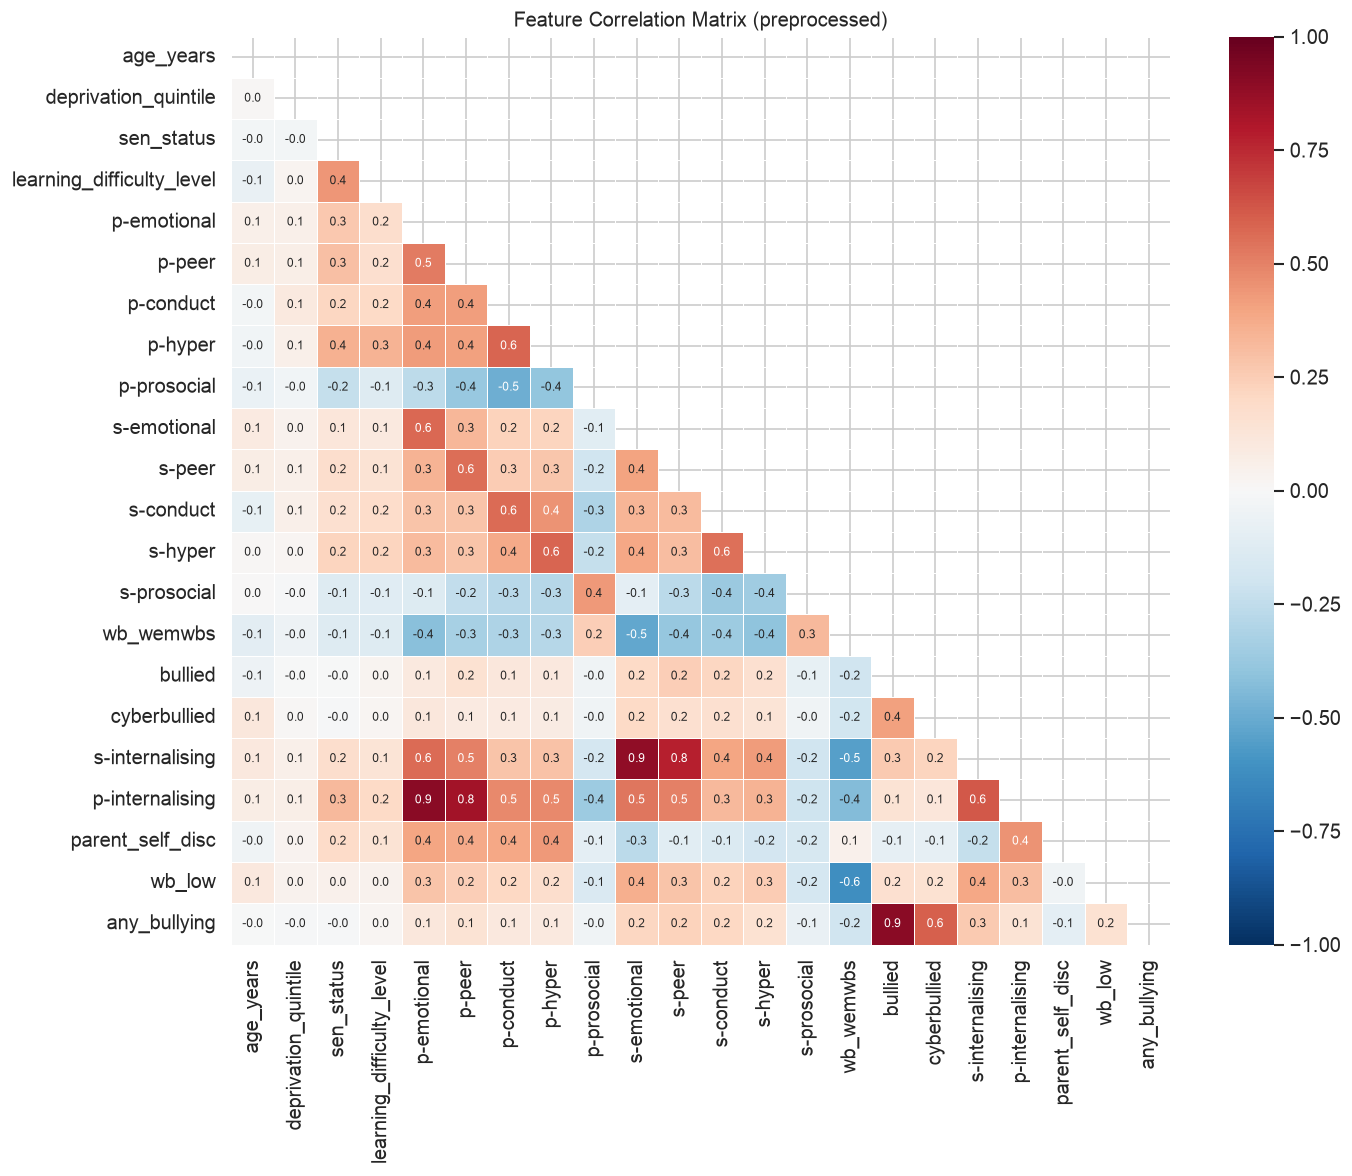

In [19]:
# Correlation heatmap of model features on full post-FE data
X_all = df_for_split[[c for c in cfg.model_feature_cols if c in df_for_split.columns]].copy()

# Use imputed values for cleaner correlation
prep_full = Preprocessor(cfg)
X_all_proc = prep_full.fit_transform(X_all)

corr = X_all_proc.corr()

# Shorten labels
short = {c: c.replace('psdq_', 'p-').replace('sdq_', 's-').replace('wellbeing_', 'wb_')
              .replace('_flag', '').replace('_discrepancy', '_disc') for c in corr.columns}
corr.rename(columns=short, index=short, inplace=True)

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.1f', linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (preprocessed)', fontsize=12)
plt.tight_layout()
plt.show()

In [20]:
# Summary statistics table for paper
summary_cols = {
    'age_years': 'Age (years)',
    'wellbeing_wemwbs': 'WEMWBS wellbeing',
    'psdq_emotional': 'Parent SDQ emotional',
    'psdq_peer': 'Parent SDQ peer',
    'sdq_emotional': 'Self SDQ emotional',
    'sdq_peer': 'Self SDQ peer',
    'bullied_flag': 'Bullied (%)',
    'cyberbullied_flag': 'Cyberbullied (%)',
    'sen_status': 'SEN (%)',
}
rows = []
for col, label in summary_cols.items():
    if col not in df_raw.columns:
        continue
    col_data = df_raw[col].dropna()
    sp  = df_raw.loc[df_raw[target] == 1, col].dropna()
    nsp = df_raw.loc[df_raw[target] == 0, col].dropna()
    rows.append({
        'Feature': label,
        'Overall mean (SD)': f'{col_data.mean():.2f} ({col_data.std():.2f})',
        'Social phobia': f'{sp.mean():.2f} ({sp.std():.2f})',
        'No social phobia': f'{nsp.mean():.2f} ({nsp.std():.2f})',
        'Missing (%)': f'{df_raw[col].isna().mean()*100:.1f}%',
    })

summary_df = pd.DataFrame(rows)
print(f'N = {len(df_raw):,}  |  Social phobia: {int(df_raw[target].sum())} ({df_raw[target].mean()*100:.1f}%)')
summary_df

N = 3,749  |  Social phobia: 75 (2.0%)


,Feature,Overall mean (SD),Social phobia,No social phobia,Missing (%)
0,Age (years),14.11 (2.19),15.59 (2.07),14.08 (2.18),0.0%
1,WEMWBS wellbeing,51.77 (9.57),36.80 (9.26),52.05 (9.34),16.6%
2,Parent SDQ emotional,2.36 (2.30),5.85 (2.56),2.30 (2.25),8.4%
3,Parent SDQ peer,1.65 (1.86),3.69 (2.34),1.61 (1.83),8.4%
4,Self SDQ emotional,2.66 (2.13),6.54 (2.00),2.59 (2.06),15.1%
5,Self SDQ peer,1.74 (1.56),3.74 (1.82),1.70 (1.53),15.1%
6,Bullied (%),0.39 (0.49),0.61 (0.49),0.39 (0.49),15.3%
7,Cyberbullied (%),0.21 (0.41),0.42 (0.50),0.21 (0.41),16.1%
8,SEN (%),0.09 (0.29),0.13 (0.34),0.09 (0.29),9.1%
